<a href="https://colab.research.google.com/github/Gloou-ui/NM/blob/main/%D0%9B%D0%B8%D1%82%D0%B2%D0%B8%D0%BD_%D0%A4%D0%86%D0%A23_10_%D0%9F%D1%80%D0%BE%D0%B3%D0%BD%D0%BE%D0%B7_%D0%B2%D1%96%D0%B4%D1%82%D0%BE%D0%BA%D1%83_%D0%BA%D0%BB%D1%96%D1%94%D0%BD%D1%82%D1%96%D0%B2.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# Практична робота: прогноз відтоку клієнтів (Customer Churn)

**Мета роботи:** побудувати модель машинного навчання, яка прогнозує, чи припинить клієнт користуватися послугами телекомунікаційної компанії.

У роботі буде використано відкритий набір даних **Telco Customer Churn**. Усі дані завантажуються безпосередньо з інтернету, тому вручну завантажені CSV-файли не потрібно для роботи.

**Етапи роботи:**
1. Імпорт бібліотек і завантаження набору даних.
2. Первинний аналіз та візуалізація.
3. Очищення й підготовка даних.
4. Поділ даних на навчальну та тестову вибірки.
5. Навчання та порівняння моделей.
6. Підбір гіперпараметрів.
7. Оцінювання найкращої моделі.
8. Прогноз для нового клієнта.
9. Висновки.

## 1. Імпорт необхідних бібліотек

In [1]:
import warnings
warnings.filterwarnings("ignore")

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.model_selection import train_test_split, GridSearchCV
from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import OneHotEncoder, StandardScaler
from sklearn.pipeline import Pipeline
from sklearn.impute import SimpleImputer
from sklearn.metrics import (
    accuracy_score, precision_score, recall_score, f1_score,
    classification_report, confusion_matrix, ConfusionMatrixDisplay,
    roc_auc_score
)
from sklearn.linear_model import LogisticRegression
from sklearn.tree import DecisionTreeClassifier
from sklearn.ensemble import RandomForestClassifier, GradientBoostingClassifier

RANDOM_STATE = 42
pd.set_option("display.max_columns", None)
sns.set_theme(style="whitegrid")

print("Бібліотеки успішно імпортовано.")

Бібліотеки успішно імпортовано.


## 2. Завантаження набору даних

Завантажимо CSV-файл Telco Customer Churn з відкритого репозиторію. Цільова ознака `Churn` показує, чи пішов клієнт (`Yes`) або залишився (`No`).

In [2]:
url = "https://raw.githubusercontent.com/rstudio/keras-customer-churn/master/data/WA_Fn-UseC_-Telco-Customer-Churn.csv"
df = pd.read_csv(url)

print("Розмір набору даних:", df.shape)
display(df.head())

Розмір набору даних: (7043, 21)


,customerID,gender,SeniorCitizen,Partner,Dependents,tenure,PhoneService,MultipleLines,InternetService,OnlineSecurity,OnlineBackup,DeviceProtection,TechSupport,StreamingTV,StreamingMovies,Contract,PaperlessBilling,PaymentMethod,MonthlyCharges,TotalCharges,Churn
0,7590-VHVEG,Female,0,Yes,No,1,No,No phone service,DSL,No,Yes,No,No,No,No,Month-to-month,Yes,Electronic check,29.85,29.85,No
1,5575-GNVDE,Male,0,No,No,34,Yes,No,DSL,Yes,No,Yes,No,No,No,One year,No,Mailed check,56.95,1889.5,No
2,3668-QPYBK,Male,0,No,No,2,Yes,No,DSL,Yes,Yes,No,No,No,No,Month-to-month,Yes,Mailed check,53.85,108.15,Yes
3,7795-CFOCW,Male,0,No,No,45,No,No phone service,DSL,Yes,No,Yes,Yes,No,No,One year,No,Bank transfer (automatic),42.30,1840.75,No
4,9237-HQITU,Female,0,No,No,2,Yes,No,Fiber optic,No,No,No,No,No,No,Month-to-month,Yes,Electronic check,70.70,151.65,Yes


## 3. Первинний аналіз даних

In [3]:
print("Інформація про набір даних:")
df.info()

print("\\nКількість пропущених значень:")
display(df.isna().sum().sort_values(ascending=False).head(10))

print("\\nСтатистичний опис числових ознак:")
display(df.describe())

Інформація про набір даних:
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 7043 entries, 0 to 7042
Data columns (total 21 columns):
 #   Column            Non-Null Count  Dtype  
---  ------            --------------  -----  
 0   customerID        7043 non-null   object 
 1   gender            7043 non-null   object 
 2   SeniorCitizen     7043 non-null   int64  
 3   Partner           7043 non-null   object 
 4   Dependents        7043 non-null   object 
 5   tenure            7043 non-null   int64  
 6   PhoneService      7043 non-null   object 
 7   MultipleLines     7043 non-null   object 
 8   InternetService   7043 non-null   object 
 9   OnlineSecurity    7043 non-null   object 
 10  OnlineBackup      7043 non-null   object 
 11  DeviceProtection  7043 non-null   object 
 12  TechSupport       7043 non-null   object 
 13  StreamingTV       7043 non-null   object 
 14  StreamingMovies   7043 non-null   object 
 15  Contract          7043 non-null   object 
 16  PaperlessBilli

,0
customerID,0
gender,0
SeniorCitizen,0
Partner,0
Dependents,0
tenure,0
PhoneService,0
MultipleLines,0
InternetService,0
OnlineSecurity,0


\nСтатистичний опис числових ознак:


,SeniorCitizen,tenure,MonthlyCharges
count,7043.000000,7043.000000,7043.000000
mean,0.162147,32.371149,64.761692
std,0.368612,24.559481,30.090047
min,0.000000,0.000000,18.250000
25%,0.000000,9.000000,35.500000
50%,0.000000,29.000000,70.350000
75%,0.000000,55.000000,89.850000
max,1.000000,72.000000,118.750000


Кількість кожного класу цільової ознаки:


,count
Churn,
No,5174
Yes,1869


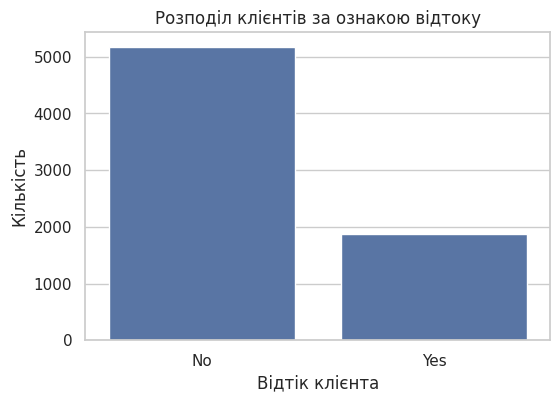

Частка клієнтів у відсотках:


,proportion
Churn,
No,73.46
Yes,26.54


In [4]:
print("Кількість кожного класу цільової ознаки:")
display(df["Churn"].value_counts())

plt.figure(figsize=(6, 4))
sns.countplot(data=df, x="Churn")
plt.title("Розподіл клієнтів за ознакою відтоку")
plt.xlabel("Відтік клієнта")
plt.ylabel("Кількість")
plt.show()

churn_percent = df["Churn"].value_counts(normalize=True) * 100
print("Частка клієнтів у відсотках:")
display(churn_percent.round(2))

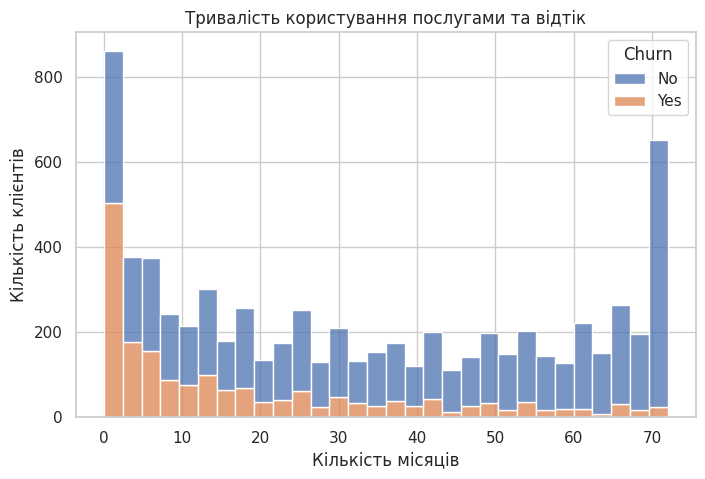

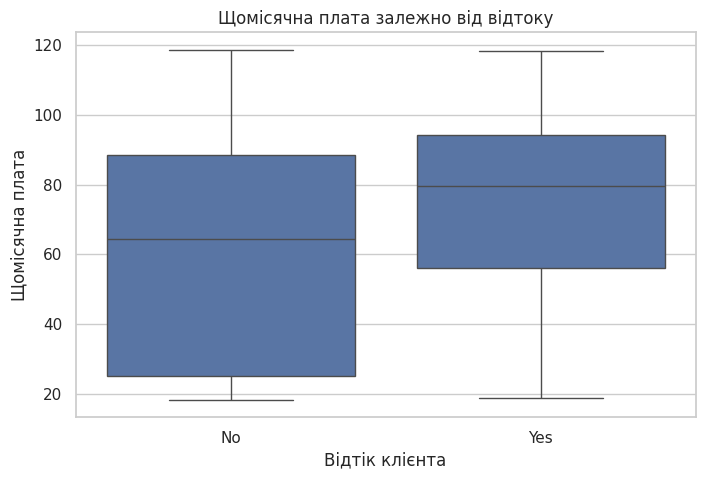

In [5]:
plt.figure(figsize=(8, 5))
sns.histplot(data=df, x="tenure", hue="Churn", bins=30, multiple="stack")
plt.title("Тривалість користування послугами та відтік")
plt.xlabel("Кількість місяців")
plt.ylabel("Кількість клієнтів")
plt.show()

plt.figure(figsize=(8, 5))
sns.boxplot(data=df, x="Churn", y="MonthlyCharges")
plt.title("Щомісячна плата залежно від відтоку")
plt.xlabel("Відтік клієнта")
plt.ylabel("Щомісячна плата")
plt.show()

## 4. Підготовка даних

Видалимо ідентифікатор клієнта `customerID`, оскільки він не несе корисної інформації для прогнозу. Ознаку `TotalCharges` перетворимо на числовий тип. Цільову ознаку закодуємо числами: `No = 0`, `Yes = 1`.

In [6]:
data = df.copy()

data["TotalCharges"] = pd.to_numeric(data["TotalCharges"], errors="coerce")
data = data.drop(columns=["customerID"])

data["Churn"] = data["Churn"].map({"No": 0, "Yes": 1})

X = data.drop(columns=["Churn"])
y = data["Churn"]

numeric_features = X.select_dtypes(include=["int64", "float64"]).columns.tolist()
categorical_features = X.select_dtypes(include=["object", "bool"]).columns.tolist()

print("Числові ознаки:", numeric_features)
print("\\nКатегоріальні ознаки:", categorical_features)
print("\\nКількість пропусків після перетворення:")
display(X.isna().sum()[X.isna().sum() > 0])

Числові ознаки: ['SeniorCitizen', 'tenure', 'MonthlyCharges', 'TotalCharges']
\nКатегоріальні ознаки: ['gender', 'Partner', 'Dependents', 'PhoneService', 'MultipleLines', 'InternetService', 'OnlineSecurity', 'OnlineBackup', 'DeviceProtection', 'TechSupport', 'StreamingTV', 'StreamingMovies', 'Contract', 'PaperlessBilling', 'PaymentMethod']
\nКількість пропусків після перетворення:


,0
TotalCharges,11


## 5. Поділ на навчальну та тестову вибірки

In [7]:
X_train, X_test, y_train, y_test = train_test_split(
    X, y,
    test_size=0.2,
    random_state=RANDOM_STATE,
    stratify=y
)

print("Навчальна вибірка:", X_train.shape)
print("Тестова вибірка:", X_test.shape)
print("Частка відтоку в навчальній вибірці:", round(y_train.mean(), 3))
print("Частка відтоку в тестовій вибірці:", round(y_test.mean(), 3))

Навчальна вибірка: (5634, 19)
Тестова вибірка: (1409, 19)
Частка відтоку в навчальній вибірці: 0.265
Частка відтоку в тестовій вибірці: 0.265


## 6. Побудова конвеєра підготовки даних

Числові ознаки заповнюємо медіаною та масштабуємо. Категоріальні ознаки заповнюємо найчастішим значенням і перетворюємо методом One-Hot Encoding. Усі перетворення виконуються всередині Pipeline, щоб уникнути витоку інформації з тестової вибірки.

In [8]:
numeric_transformer = Pipeline(steps=[
    ("imputer", SimpleImputer(strategy="median")),
    ("scaler", StandardScaler())
])

categorical_transformer = Pipeline(steps=[
    ("imputer", SimpleImputer(strategy="most_frequent")),
    ("onehot", OneHotEncoder(handle_unknown="ignore"))
])

preprocessor = ColumnTransformer(transformers=[
    ("num", numeric_transformer, numeric_features),
    ("cat", categorical_transformer, categorical_features)
])

print("Конвеєр підготовки даних створено.")

Конвеєр підготовки даних створено.


## 7. Навчання та порівняння моделей

Навчимо чотири алгоритми класифікації: логістичну регресію, дерево рішень, випадковий ліс і градієнтний бустинг. Для порівняння використаємо Accuracy, Precision, Recall, F1-score та ROC-AUC.

In [9]:
models = {
    "Logistic Regression": LogisticRegression(max_iter=2000, class_weight="balanced", random_state=RANDOM_STATE),
    "Decision Tree": DecisionTreeClassifier(class_weight="balanced", random_state=RANDOM_STATE),
    "Random Forest": RandomForestClassifier(n_estimators=200, class_weight="balanced", random_state=RANDOM_STATE, n_jobs=-1),
    "Gradient Boosting": GradientBoostingClassifier(random_state=RANDOM_STATE)
}

results = []
trained_models = {}

for name, model in models.items():
    pipeline = Pipeline(steps=[
        ("preprocessor", preprocessor),
        ("model", model)
    ])
    pipeline.fit(X_train, y_train)
    predictions = pipeline.predict(X_test)
    probabilities = pipeline.predict_proba(X_test)[:, 1]

    results.append({
        "Модель": name,
        "Accuracy": accuracy_score(y_test, predictions),
        "Precision": precision_score(y_test, predictions, zero_division=0),
        "Recall": recall_score(y_test, predictions, zero_division=0),
        "F1-score": f1_score(y_test, predictions, zero_division=0),
        "ROC-AUC": roc_auc_score(y_test, probabilities)
    })
    trained_models[name] = pipeline

comparison = pd.DataFrame(results).sort_values("F1-score", ascending=False).reset_index(drop=True)
display(comparison.round(4))

,Модель,Accuracy,Precision,Recall,F1-score,ROC-AUC
0,Logistic Regression,0.7381,0.5043,0.7834,0.6136,0.8413
1,Gradient Boosting,0.8062,0.6735,0.5241,0.5895,0.8434
2,Random Forest,0.7828,0.6181,0.4759,0.5378,0.8220
3,Decision Tree,0.7282,0.4878,0.4813,0.4845,0.6496


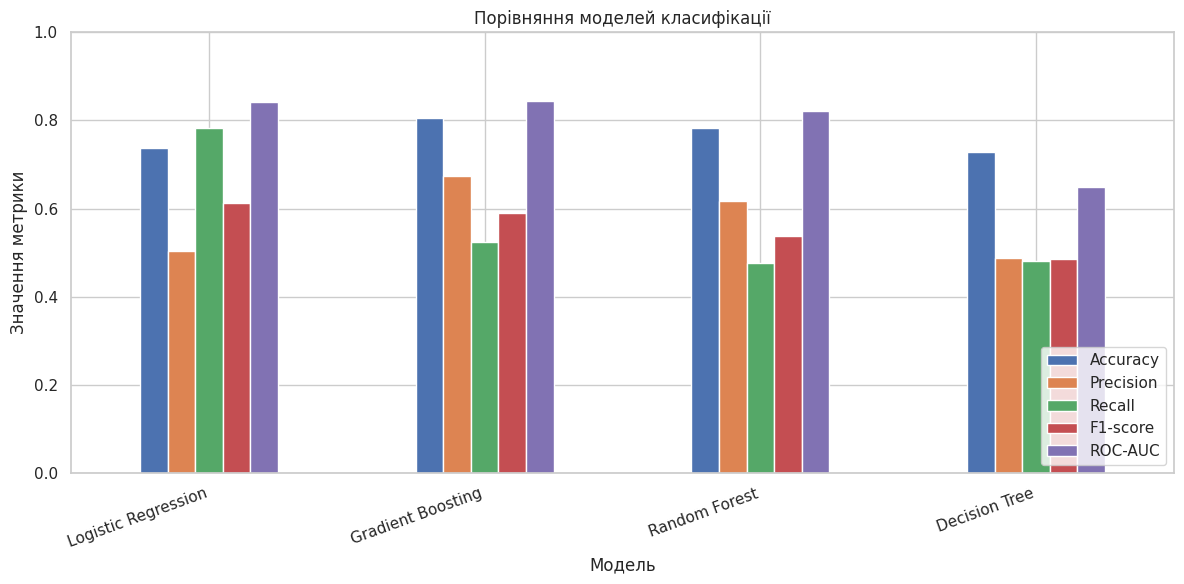

In [10]:
comparison.set_index("Модель")[["Accuracy", "Precision", "Recall", "F1-score", "ROC-AUC"]].plot(
    kind="bar", figsize=(12, 6)
)
plt.title("Порівняння моделей класифікації")
plt.ylabel("Значення метрики")
plt.ylim(0, 1)
plt.xticks(rotation=20, ha="right")
plt.legend(loc="lower right")
plt.tight_layout()
plt.show()

## 8. Підбір гіперпараметрів найкращої базової моделі

Для подальшого налаштування виберемо випадковий ліс (Random Forest), оскільки це ансамблевий алгоритм, який добре працює з різними типами ознак. Підбір виконаємо за F1-score на навчальних даних за допомогою кросвалідації.

In [11]:
rf_pipeline = Pipeline(steps=[
    ("preprocessor", preprocessor),
    ("model", RandomForestClassifier(
        class_weight="balanced",
        random_state=RANDOM_STATE,
        n_jobs=-1
    ))
])

param_grid = {
    "model__n_estimators": [150, 250],
    "model__max_depth": [None, 10, 20],
    "model__min_samples_split": [2, 5]
}

grid_search = GridSearchCV(
    estimator=rf_pipeline,
    param_grid=param_grid,
    scoring="f1",
    cv=3,
    n_jobs=-1,
    verbose=1
)

grid_search.fit(X_train, y_train)

print("Найкращі параметри:")
print(grid_search.best_params_)
print("Найкращий середній F1-score на крос-валідації:", round(grid_search.best_score_, 4))

best_model = grid_search.best_estimator_

Fitting 3 folds for each of 12 candidates, totalling 36 fits
Найкращі параметри:
{'model__max_depth': 10, 'model__min_samples_split': 5, 'model__n_estimators': 150}
Найкращий середній F1-score на крос-валідації: 0.6333


## 9. Оцінювання налаштованої моделі

Результати найкращої налаштованої моделі:
Accuracy: 0.7715
Precision: 0.5533
Recall: 0.7219
F1-score: 0.6265
ROC-AUC: 0.8394
\nДетальний звіт класифікації:
              precision    recall  f1-score   support

  Залишиться       0.89      0.79      0.84      1035
        Піде       0.55      0.72      0.63       374

    accuracy                           0.77      1409
   macro avg       0.72      0.76      0.73      1409
weighted avg       0.80      0.77      0.78      1409



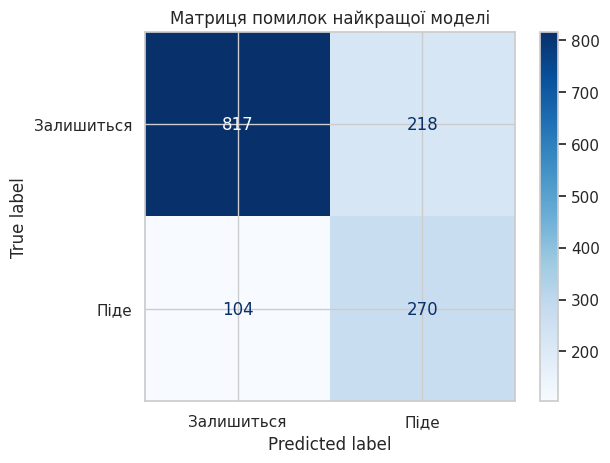

In [12]:
best_predictions = best_model.predict(X_test)
best_probabilities = best_model.predict_proba(X_test)[:, 1]

print("Результати найкращої налаштованої моделі:")
print("Accuracy:", round(accuracy_score(y_test, best_predictions), 4))
print("Precision:", round(precision_score(y_test, best_predictions, zero_division=0), 4))
print("Recall:", round(recall_score(y_test, best_predictions, zero_division=0), 4))
print("F1-score:", round(f1_score(y_test, best_predictions, zero_division=0), 4))
print("ROC-AUC:", round(roc_auc_score(y_test, best_probabilities), 4))

print("\\nДетальний звіт класифікації:")
print(classification_report(y_test, best_predictions, target_names=["Залишиться", "Піде"], zero_division=0))

ConfusionMatrixDisplay.from_predictions(
    y_test, best_predictions,
    display_labels=["Залишиться", "Піде"],
    cmap="Blues"
)
plt.title("Матриця помилок найкращої моделі")
plt.show()

## 10. Порівняння базової та налаштованої моделей

In [13]:
tuned_row = {
    "Модель": "Random Forest (після підбору)",
    "Accuracy": accuracy_score(y_test, best_predictions),
    "Precision": precision_score(y_test, best_predictions, zero_division=0),
    "Recall": recall_score(y_test, best_predictions, zero_division=0),
    "F1-score": f1_score(y_test, best_predictions, zero_division=0),
    "ROC-AUC": roc_auc_score(y_test, best_probabilities)
}

final_comparison = pd.concat(
    [comparison, pd.DataFrame([tuned_row])],
    ignore_index=True
).sort_values("F1-score", ascending=False).reset_index(drop=True)

display(final_comparison.round(4))

,Модель,Accuracy,Precision,Recall,F1-score,ROC-AUC
0,Random Forest (після підбору),0.7715,0.5533,0.7219,0.6265,0.8394
1,Logistic Regression,0.7381,0.5043,0.7834,0.6136,0.8413
2,Gradient Boosting,0.8062,0.6735,0.5241,0.5895,0.8434
3,Random Forest,0.7828,0.6181,0.4759,0.5378,0.8220
4,Decision Tree,0.7282,0.4878,0.4813,0.4845,0.6496


## 11. Прогноз для нового клієнта

У цій комірці можна змінити характеристики клієнта. Значення мають відповідати назвам і форматам ознак із набору даних. Після запуску модель виведе прогноз: клієнт піде чи залишиться, а також імовірність відтоку.

Наведений нижче приклад є демонстраційним — замініть значення на характеристики потрібного клієнта.

In [14]:
new_customer = {
    "gender": "Female",
    "SeniorCitizen": 0,
    "Partner": "Yes",
    "Dependents": "No",
    "tenure": 2,
    "PhoneService": "Yes",
    "MultipleLines": "No",
    "InternetService": "Fiber optic",
    "OnlineSecurity": "No",
    "OnlineBackup": "No",
    "DeviceProtection": "No",
    "TechSupport": "No",
    "StreamingTV": "No",
    "StreamingMovies": "No",
    "Contract": "Month-to-month",
    "PaperlessBilling": "Yes",
    "PaymentMethod": "Electronic check",
    "MonthlyCharges": 85.70,
    "TotalCharges": 170.0
}

customer_df = pd.DataFrame([new_customer], columns=X.columns)

churn_prediction = best_model.predict(customer_df)[0]
churn_probability = best_model.predict_proba(customer_df)[0, 1]

if churn_prediction == 1:
    print("Прогноз: КЛІЄНТ ПІДЕ.")
else:
    print("Прогноз: КЛІЄНТ ЗАЛИШИТЬСЯ.")

print(f"Імовірність відтоку: {churn_probability:.1%}")
print(f"Імовірність залишитися: {1 - churn_probability:.1%}")

Прогноз: КЛІЄНТ ПІДЕ.
Імовірність відтоку: 81.8%
Імовірність залишитися: 18.2%


## 12. Висновки

В ході роботи навчилися моделювати відток клієнтів та прогнозувати щого. Дослідили набір даних Telco Customer Churn який містить інформацію про клієнтів телекомунікаційної компанії. Ми адаптували данні для навчання моделей. Після навчання порівняли чотири види алгоритму класифікації, а для моделі випадкового лісу додатково виконано підбір гіперпараметрів. Те на скіки модель якісно та добре працює оцінили за метриками Accuracy, Precision, Recall, F1-score та ROC-AUC, й обрали як основу самий найкращий варіант а саме F1-score. Ця модель вміє прогнозувати відток нових клієнтів й за цим визначати, чи буде клієнт продовжувати користуватись послугами чи ні, що правда в рамках тих данних на яких вчилась модель, при якихось незвичайних умовах може спрогнозувати інакше.